# Multimodal Alzheimer's Disease Classification — Results Visualizer

This notebook dynamically loads, aggregates, and visualizes 5-fold cross-validation performance across all model architectures and classification tasks.

### Structure:
- **Rows:** One row per model architecture (dynamically discovered from `models/` via `os.listdir`).
- **Columns (Two Levels):**
  - **Level 1 (Task):** `CN vs AD`, `CN vs MCI`, `MCI vs AD`, `CN vs MCI vs AD`
  - **Level 2 (Metric):** `ACC`, `F1`, `AUC`, `Loss`
- **Values:** Cross-validation $\text{mean} \pm \text{std}$ across evaluated folds.

In [1]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Visualization settings
sns.set_theme(style="whitegrid", font_scale=1.1)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 1000)

## 1. Configuration & Task/Metric Definitions

Define project paths, target model architectures, task labels, and evaluation metrics.

In [2]:
# Project directory and model outputs path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR = PROJECT_ROOT / "models"

# Obtain models dynamically from models directory via os.listdir
MODELS = sorted([
    m for m in os.listdir(MODELS_DIR)
    if os.path.isdir(os.path.join(MODELS_DIR, m)) and not m.startswith(".")
])

# Classification tasks: directory name -> display name
TASKS = {
    "cn_ad": "CN vs AD",
    "cn_mci": "CN vs MCI",
    "mci_ad": "MCI vs AD",
    "cn_mci_ad": "CN vs MCI vs AD",
}

# Metrics: JSON key -> display label
METRICS = {
    "acc": "ACC",
    "f1-score": "F1",
    "auc": "AUC",
    "loss": "Loss",
}

print(f"Project root: {PROJECT_ROOT}")
print(f"Models directory: {MODELS_DIR} (exists: {MODELS_DIR.exists()})")
print(f"Discovered models via os.listdir ({len(MODELS)}): {MODELS}")
print(f"Tasks: {list(TASKS.values())}")
print(f"Metrics: {list(METRICS.values())}")

Project root: /leonardo_scratch/fast/IscrC_ISAAC/raffaele/multimodal-alzheimer-classification
Models directory: /leonardo_scratch/fast/IscrC_ISAAC/raffaele/multimodal-alzheimer-classification/models (exists: True)
Discovered models via os.listdir (7): ['densenet', 'population_gcn', 'resnet18', 'resnet34', 'resnet50', 'swin_vit', 'vit']
Tasks: ['CN vs AD', 'CN vs MCI', 'MCI vs AD', 'CN vs MCI vs AD']
Metrics: ['ACC', 'F1', 'AUC', 'Loss']


## 2. Load Results & Aggregate Cross-Validation Folds

Parse `test_metrics.json` from `models/<model>/<task>/<fold>/` across all folds and compute fold statistics.

In [3]:
def load_experiment_results(models_dir=MODELS_DIR, models=None, tasks=TASKS, metrics=METRICS, precision=4):
    """
    Scans models_dir and loads test_metrics.json for each model, task, and fold.
    
    Returns:
        df_summary: pd.DataFrame with models as rows and MultiIndex columns (Task, Metric) formatted as mean ± std
        df_mean: pd.DataFrame with numeric means
        df_std: pd.DataFrame with numeric standard deviations
        df_folds: pd.DataFrame containing individual fold-level metrics
    """
    fold_records = []
    
    # Obtain models dynamically via os.listdir if not explicitly passed
    if models is None:
        models = sorted([
            m for m in os.listdir(models_dir)
            if os.path.isdir(os.path.join(models_dir, m)) and not m.startswith(".")
        ])
    all_models = list(models)
                
    for model in all_models:
        for task_key, task_label in tasks.items():
            task_dir = models_dir / model / task_key
            if not task_dir.exists():
                continue
            for fold_dir in sorted(task_dir.iterdir()):
                if not fold_dir.is_dir():
                    continue
                metric_file = fold_dir / "test_metrics.json"
                if metric_file.exists():
                    try:
                        with open(metric_file, "r") as f:
                            m = json.load(f)
                        record = {
                            "model": model,
                            "task_key": task_key,
                            "task": task_label,
                            "fold": fold_dir.name,
                        }
                        for m_key, m_label in metrics.items():
                            if m_key in m:
                                record[m_label] = float(m[m_key])
                        fold_records.append(record)
                    except Exception as e:
                        print(f"Warning: Failed reading {metric_file}: {e}")
                        
    df_folds = pd.DataFrame(fold_records)
    
    # MultiIndex columns: Level 0 = Task, Level 1 = Metric
    col_multiindex = pd.MultiIndex.from_product(
        [list(tasks.values()), list(metrics.values())],
        names=["Task", "Metric"]
    )
    
    if df_folds.empty:
        print("No test_metrics.json files found yet.")
        empty_summary = pd.DataFrame("—", index=all_models, columns=col_multiindex)
        empty_numeric = pd.DataFrame(np.nan, index=all_models, columns=col_multiindex)
        return empty_summary, empty_numeric, empty_numeric, df_folds

    # Aggregate across folds
    agg_records = []
    for model in all_models:
        model_sub = df_folds[df_folds["model"] == model]
        for task_key, task_label in tasks.items():
            task_sub = model_sub[model_sub["task"] == task_label]
            for m_label in metrics.values():
                if m_label in task_sub.columns and len(task_sub[m_label].dropna()) > 0:
                    vals = task_sub[m_label].dropna().values
                    mean_val = float(np.mean(vals))
                    std_val = float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0
                    n_folds = len(vals)
                    
                    if n_folds > 1:
                        formatted = f"{mean_val:.{precision}f} ± {std_val:.{precision}f}"
                    else:
                        formatted = f"{mean_val:.{precision}f}"
                        
                    agg_records.append({
                        "model": model,
                        "task": task_label,
                        "metric": m_label,
                        "mean": mean_val,
                        "std": std_val,
                        "count": n_folds,
                        "formatted": formatted,
                    })

    df_agg = pd.DataFrame(agg_records)
    
    df_summary = (
        df_agg.pivot(index="model", columns=["task", "metric"], values="formatted")
        .reindex(index=all_models, columns=col_multiindex)
        .fillna("—")
    )
    
    df_mean = (
        df_agg.pivot(index="model", columns=["task", "metric"], values="mean")
        .reindex(index=all_models, columns=col_multiindex)
    )
    
    df_std = (
        df_agg.pivot(index="model", columns=["task", "metric"], values="std")
        .reindex(index=all_models, columns=col_multiindex)
    )
    
    return df_summary, df_mean, df_std, df_folds

df_summary, df_mean, df_std, df_folds = load_experiment_results()

## 3. Results Summary Table

The requested table displaying:
- **One row per model**
- **Two-level MultiIndex columns:** `Task` $\rightarrow$ `Metric`
- **Values:** Cross-validation $\text{mean} \pm \text{std}$ (or single-fold value if in progress, `—` if pending)

In [4]:
display(df_summary)

Task                   CN vs AD                                                           CN vs MCI                                                           MCI vs AD                                                     CN vs MCI vs AD                                                   
Metric                      ACC               F1              AUC             Loss              ACC               F1              AUC             Loss              ACC               F1              AUC             Loss              ACC               F1              AUC             Loss
model                                                                                                                                                                                                                                                                                         
densenet        0.5671 ± 0.0871  0.4917 ± 0.0792  0.6589 ± 0.0774  0.0779 ± 0.0055  0.5242 ± 0.0533  0.5835 ± 0.0869  0.5285 ± 0.0598  0.0853 ± 0.0066  0.6085 ± 0.1152  0.3275 ± 0.0573  0.6006 ± 0.0833  0.0641 ± 0.0101  0.3462 ± 0.0240  0.2498 ± 0.0377  0.5274 ± 0.0207  0.1295 ± 0.0032
population_gcn  0.5516 ± 0.1301  0.4119 ± 0.0418  0.5494 ± 0.0739  0.0910 ± 0.0120  0.4688 ± 0.0262  0.4576 ± 0.0658  0.5151 ± 0.0373  0.0801 ± 0.0029  0.6244 ± 0.1252  0.3510 ± 0.0386  0.6031 ± 0.0449  0.0556 ± 0.0016  0.3899 ± 0.0273  0.2531 ± 0.0683  0.5546 ± 0.0242  0.1188 ± 0.0011
resnet18        0.6055 ± 0.1056  0.3953 ± 0.0957  0.5795 ± 0.0624  0.0869 ± 0.0098  0.3940 ± 0.0399  0.2686 ± 0.1727  0.4607 ± 0.0441  0.0911 ± 0.0045  0.5205 ± 0.0999  0.3051 ± 0.0474  0.5231 ± 0.0858  0.0624 ± 0.0065  0.3362 ± 0.0454  0.2408 ± 0.0507  0.5041 ± 0.0322  0.1444 ± 0.0220
resnet34        0.6493 ± 0.0840  0.5274 ± 0.1071  0.6840 ± 0.1211  0.0725 ± 0.0109  0.4340 ± 0.0295  0.4255 ± 0.0548  0.4734 ± 0.0543  0.0917 ± 0.0081  0.6972 ± 0.0621  0.2447 ± 0.1414  0.5763 ± 0.0895  0.0581 ± 0.0041  0.3340 ± 0.0129  0.2487 ± 0.0196  0.4975 ± 0.0332  0.1330 ± 0.0094
resnet50        0.6502 ± 0.1284  0.4654 ± 0.1282  0.6793 ± 0.1628  0.0714 ± 0.0099  0.4493 ± 0.0422  0.4312 ± 0.0962  0.4673 ± 0.0242  0.0833 ± 0.0029  0.6591 ± 0.1172  0.2765 ± 0.1154  0.6073 ± 0.0520  0.0576 ± 0.0046  0.3513 ± 0.0501  0.2682 ± 0.0447  0.5388 ± 0.0458  0.1355 ± 0.0125
swin_vit        0.5945 ± 0.0114  0.3775 ± 0.0912  0.5393 ± 0.0736  0.0758 ± 0.0067  0.3935 ± 0.0367  0.2768 ± 0.1061  0.4777 ± 0.0354  0.0807 ± 0.0016  0.7472 ± 0.0226  0.2139 ± 0.0677  0.5690 ± 0.0653  0.0551 ± 0.0006  0.3588 ± 0.0272  0.2838 ± 0.0444  0.5058 ± 0.0115  0.1238 ± 0.0017
vit             0.5041 ± 0.0150  0.4811 ± 0.0084  0.5960 ± 0.0328  0.0710 ± 0.0021  0.4567 ± 0.0857  0.3962 ± 0.2705  0.5068 ± 0.0348  0.0821 ± 0.0037  0.6170 ± 0.0737  0.3374 ± 0.1152  0.6599 ± 0.0188  0.0504 ± 0.0009  0.3534 ± 0.0366  0.2877 ± 0.0360  0.5154 ± 0.0228  0.1252 ± 0.0060

## 4. Highlighted Comparison Table

Visual heatmap view on mean metric values across models:
- **Green highlight:** Highest value for `ACC`, `F1`, and `AUC` (higher is better)
- **Yellow highlight:** Lowest value for `Loss` (lower is better)

In [5]:
def style_results(df):
    styles = df.style
    styles = styles.format(lambda v: f"{v:.4f}" if pd.notnull(v) and isinstance(v, (int, float)) else "—")
    for task in TASKS.values():
        for metric in ["ACC", "F1", "AUC"]:
            if (task, metric) in df.columns:
                styles = styles.highlight_max(subset=[(task, metric)], color="#c8e6c9")
        if (task, "Loss") in df.columns:
            styles = styles.highlight_min(subset=[(task, "Loss")], color="#ffecb3")
    return styles

style_results(df_mean)

## 5. Graphical Comparison Across Tasks

Bar charts with error bars (standard deviation across folds) comparing available models for `ACC`, `F1`, and `AUC`.

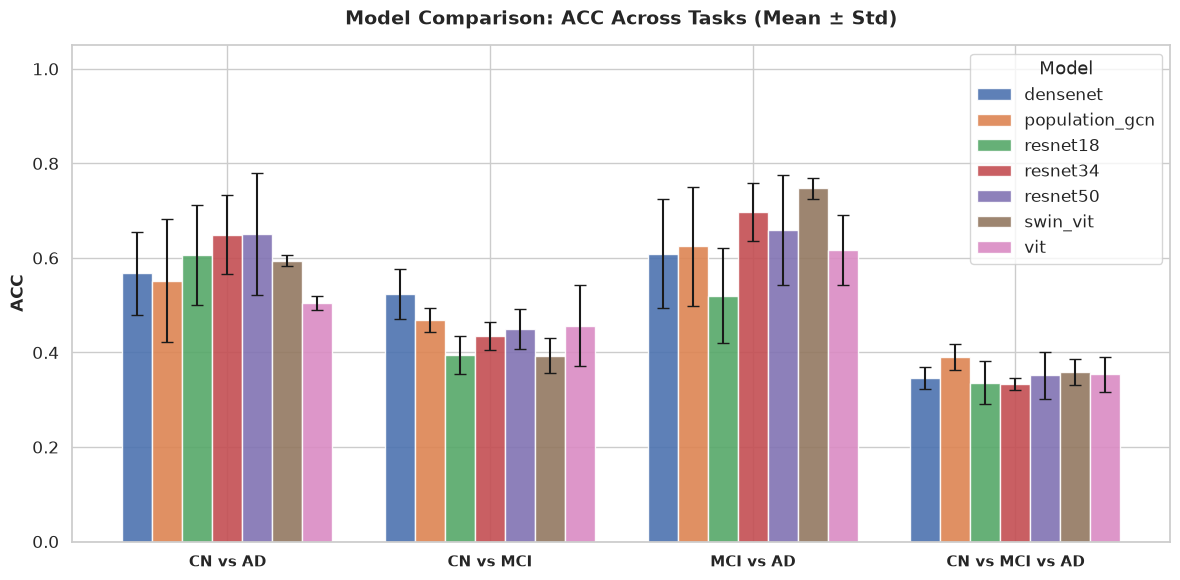

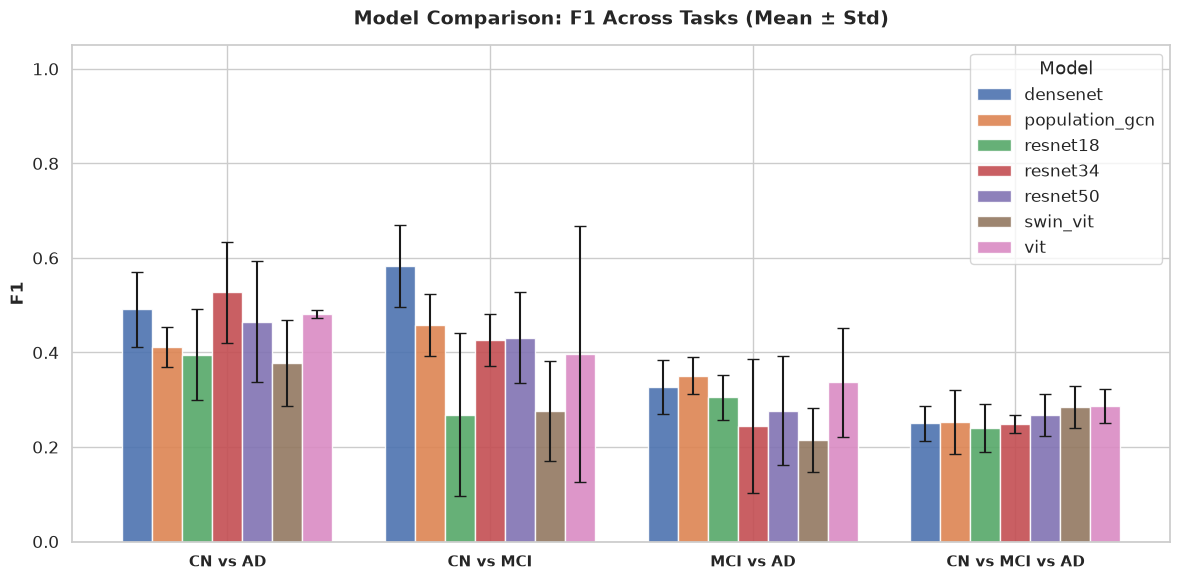

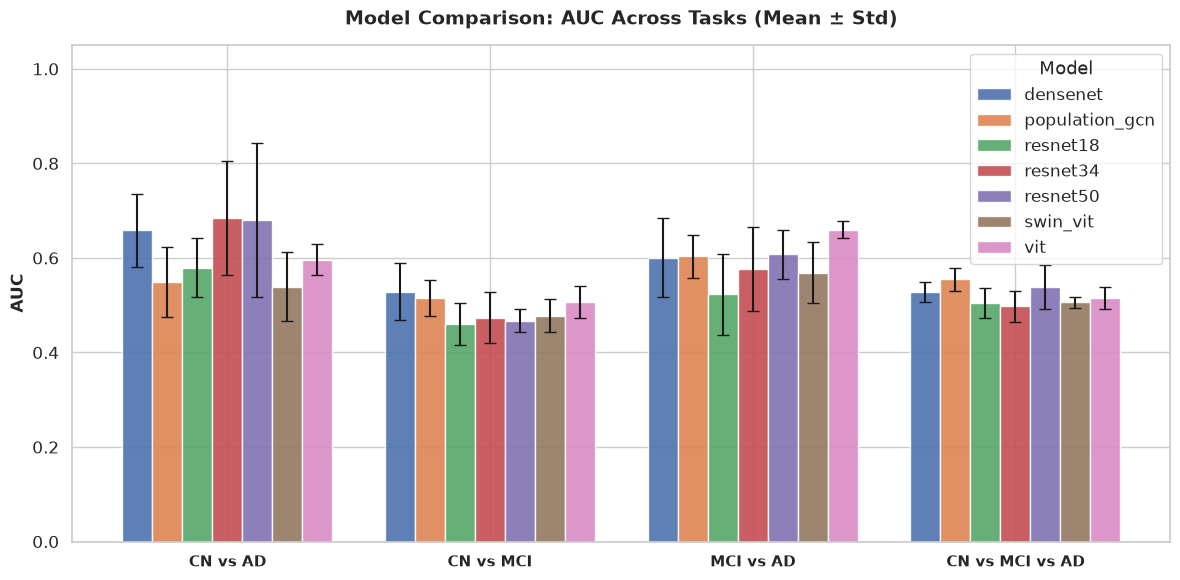

In [6]:
def plot_metric_across_tasks(metric_name="ACC", df_mean=df_mean, df_std=df_std):
    completed_models = df_mean.dropna(how="all").index.tolist()
    if not completed_models:
        print(f"No completed models to plot for {metric_name}.")
        return
        
    tasks_list = list(TASKS.values())
    x = np.arange(len(tasks_list))
    width = 0.8 / max(len(completed_models), 1)
    
    fig, ax = plt.subplots(figsize=(12, 6))
    colors = sns.color_palette("deep", len(completed_models))
    
    for i, model in enumerate(completed_models):
        means = [df_mean.loc[model, (task, metric_name)] if (task, metric_name) in df_mean.columns else np.nan for task in tasks_list]
        stds = [df_std.loc[model, (task, metric_name)] if (task, metric_name) in df_std.columns else 0.0 for task in tasks_list]
        means_plot = [0 if np.isnan(m) else m for m in means]
        stds_plot = [0 if np.isnan(s) else s for s in stds]
        
        ax.bar(
            x + i * width,
            means_plot,
            width,
            yerr=stds_plot,
            capsize=4,
            label=model,
            color=colors[i],
            alpha=0.9
        )
        
    ax.set_ylabel(metric_name, fontsize=12, fontweight="bold")
    ax.set_title(f"Model Comparison: {metric_name} Across Tasks (Mean ± Std)", fontsize=14, fontweight="bold", pad=15)
    ax.set_xticks(x + width * (len(completed_models) - 1) / 2)
    ax.set_xticklabels(tasks_list, fontsize=11, fontweight="bold")
    ax.legend(title="Model", frameon=True)
    ax.set_ylim(0, 1.05 if metric_name != "Loss" else max(0.5, np.nanmax(df_mean.values) * 1.2))
    plt.tight_layout()
    plt.show()

for metric in ["ACC", "F1", "AUC"]:
    plot_metric_across_tasks(metric)

## 6. Detailed Fold-by-Fold Inspection

Inspect individual cross-validation fold values to examine variance and stability across data partitions.

In [7]:
if not df_folds.empty:
    display_cols = ["model", "task", "fold", "ACC", "F1", "AUC", "Loss"]
    print(f"Total evaluated fold checkpoints: {len(df_folds)}")
    display(df_folds[display_cols].sort_values(by=["model", "task", "fold"]))
else:
    print("No fold records found.")

Total evaluated fold checkpoints: 140


,model,task,fold,ACC,F1,AUC,Loss
0,densenet,CN vs AD,0,0.497717,0.408602,0.573634,0.0799
1,densenet,CN vs AD,1,0.506849,0.406593,0.586769,0.0802
2,densenet,CN vs AD,2,0.529680,0.525346,0.665388,0.0829
3,densenet,CN vs AD,3,0.593607,0.538860,0.730585,0.0777
4,densenet,CN vs AD,4,0.707763,0.578947,0.738159,0.0686
5,densenet,CN vs MCI,0,0.469767,0.488789,0.511190,0.0949
6,densenet,CN vs MCI,1,0.604651,0.685185,0.610356,0.0799
7,densenet,CN vs MCI,2,0.495349,0.529284,0.549524,0.0815
8,densenet,CN vs MCI,3,0.502326,0.548523,0.525783,0.0808
9,densenet,CN vs MCI,4,0.548837,0.665517,0.445747,0.0895


## 7. Export Results (CSV & LaTeX)

Export tables directly for publications or reports.

In [8]:
output_csv = MODELS_DIR / "cross_validation_results.csv"
df_summary.to_csv(output_csv)
print(f"Saved CSV results to: {output_csv}")

latex_str = df_summary.to_latex(
    caption="5-Fold Cross-Validation Performance Across Tasks and Models.",
    label="tab:multimodal_ad_results",
    multicolumn=True,
    multirow=True,
)
print("\nLaTeX Table Representation:\n")
print(latex_str)

Saved CSV results to: /leonardo_scratch/fast/IscrC_ISAAC/raffaele/multimodal-alzheimer-classification/models/cross_validation_results.csv

LaTeX Table Representation:

\begin{table}
\caption{5-Fold Cross-Validation Performance Across Tasks and Models.}
\label{tab:multimodal_ad_results}
\begin{tabular}{lllllllllllllllll}
\toprule
Task & \multicolumn{4}{r}{CN vs AD} & \multicolumn{4}{r}{CN vs MCI} & \multicolumn{4}{r}{MCI vs AD} & \multicolumn{4}{r}{CN vs MCI vs AD} \\
Metric & ACC & F1 & AUC & Loss & ACC & F1 & AUC & Loss & ACC & F1 & AUC & Loss & ACC & F1 & AUC & Loss \\
model &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  \\
\midrule
densenet & 0.5671 ± 0.0871 & 0.4917 ± 0.0792 & 0.6589 ± 0.0774 & 0.0779 ± 0.0055 & 0.5242 ± 0.0533 & 0.5835 ± 0.0869 & 0.5285 ± 0.0598 & 0.0853 ± 0.0066 & 0.6085 ± 0.1152 & 0.3275 ± 0.0573 & 0.6006 ± 0.0833 & 0.0641 ± 0.0101 & 0.3462 ± 0.0240 & 0.2498 ± 0.0377 & 0.5274 ± 0.0207 & 0.1295 ± 0.0032 \\
population_gcn & 0.5516 ± 0.1301 & 0.4119 ± 0.0418 & 0.5